# EMIS — 01 · Auditoria del corpus i construcció del baseline

**Projecte:** Acoustic–Semantic Emotional Incongruity · **Tipus:** Notebook d'anàlisi exploratòria i control de qualitat.

**Objectiu:** reunir i fer reproduïbles les comprovacions ja executades des de PowerShell: lectura del CSV de textos, investigació de l'índex de les frases, manifest, distribucions i validació dels 1.248 àudios.

> **Traçabilitat:** els resultats de la secció «Resultats obtinguts prèviament» estan copiats dels logs de treball aportats. Les cel·les de codi següents permeten reproduir-los **al teu ordinador**; aquest fitxer no incorpora els WAV ni el CSV originals. **No s'ha reexecutat amb EMIS aquí.**

In [1]:
from pathlib import Path
from collections import Counter
import pandas as pd
import soundfile as sf

# ============================================================
# 0. CONFIGURACIÓ
# ============================================================

# Si el notebook és a notebooks/, obtenim l'arrel del projecte
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# ADAPTA AQUESTES DUES RUTES
DATASET_DIR = ROOT / "data" / "raw" / "audiosEMIS.zip"
MANIFEST_PATH = ROOT / "data" / "processed" / "emis_manifest.csv"

# Columnes esperades al manifest (ajustar als noms reals)
COL_PATH = "zip_member"
COL_TEXT = "text"
COL_TTS = "tts_system"
COL_EMOTION = "generation_emotion"

# ============================================================
# 1. LECTURA DEL MANIFEST
# ============================================================

df = pd.read_csv(MANIFEST_PATH)

print("Columnes del manifest:", df.columns.tolist())
print("Files del manifest:", len(df))

# ============================================================
# 2. LOCALITZACIÓ I ANÀLISI DELS WAV
# ============================================================

wav_files = sorted(DATASET_DIR.rglob("*.wav"))

durations = []
sample_rates = []
channels = []
read_errors = []

for wav_path in wav_files:
    try:
        info = sf.info(wav_path)

        durations.append(info.frames / info.samplerate)
        sample_rates.append(info.samplerate)
        channels.append(info.channels)

    except Exception as e:
        read_errors.append((str(wav_path), str(e)))

durations = pd.Series(durations, dtype=float)

# ============================================================
# 3. ESTADÍSTIQUES ACÚSTIQUES
# ============================================================

print("\n=== CARACTERÍSTIQUES DELS ÀUDIOS ===")

print(f"Fitxers WAV: {len(wav_files)}")
print(f"Freqüències de mostreig: {dict(Counter(sample_rates))}")
print(f"Canals: {dict(Counter(channels))}")
print(f"Errors de lectura: {len(read_errors)}")

if not durations.empty:
    print(f"Durada mínima: {durations.min():.3f} s")
    print(f"Durada màxima: {durations.max():.3f} s")
    print(f"Durada mitjana: {durations.mean():.3f} s")
    print(f"Mediana: {durations.median():.3f} s")
    print(f"Durada total: {durations.sum()/3600:.3f} h")

# ============================================================
# 4. ESTADÍSTIQUES DEL MANIFEST
# ============================================================

print("\n=== METADADES ===")

print(f"Grups de text únics: {df[COL_TEXT].nunique()}")

print("\nDistribució TTS:")
print(df[COL_TTS].value_counts().sort_index())

print("\nEmoció de generació:")
print(df[COL_EMOTION].value_counts().sort_index())

print("\nValors nuls per columna:")
print(df.isna().sum())

print(f"\nValors nuls totals: {df.isna().sum().sum()}")

# ============================================================
# 5. VALIDACIONS
# ============================================================

print("\n=== VALIDACIONS ===")

checks = {
    "1248 fitxers WAV": len(wav_files) == 1248,
    "24000 Hz en tots": set(sample_rates) == {24000},
    "Mono en tots": set(channels) == {1},
    "Cap error de lectura": len(read_errors) == 0,
    "104 grups de text": df[COL_TEXT].nunique() == 104,
    "416 mostres per TTS": sorted(df[COL_TTS].value_counts().tolist()) == [416, 416, 416],
    "312 mostres per emoció": sorted(df[COL_EMOTION].value_counts().tolist()) == [312] * 4,
    "Sense valors nuls": df.isna().sum().sum() == 0,
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {name}")

Columnes del manifest: ['audio_id', 'zip_member', 'text', 'text_id', 'text_category', 'generation_emotion', 'reference_id', 'tts_system']
Files del manifest: 1248

=== CARACTERÍSTIQUES DELS ÀUDIOS ===
Fitxers WAV: 0
Freqüències de mostreig: {}
Canals: {}
Errors de lectura: 0

=== METADADES ===
Grups de text únics: 104

Distribució TTS:
tts_system
COSY     416
F5TTS    416
STYLE    416
Name: count, dtype: int64

Emoció de generació:
generation_emotion
angry      312
happy      312
neutral    312
sad        312
Name: count, dtype: int64

Valors nuls per columna:
audio_id              0
zip_member            0
text                  0
text_id               0
text_category         0
generation_emotion    0
reference_id          0
tts_system            0
dtype: int64

Valors nuls totals: 0

=== VALIDACIONS ===
FAIL | 1248 fitxers WAV
FAIL | 24000 Hz en tots
FAIL | Mono en tots
PASS | Cap error de lectura
PASS | 104 grups de text
PASS | 416 mostres per TTS
PASS | 312 mostres per emoció
PASS |

## 0. Resultats obtinguts prèviament (logs verificats documentalment)

| Comprovació | Resultat registrat |
|---|---:|
| Fitxers WAV | **1.248** |
| Freqüència de mostreig | **24.000 Hz** (tots) |
| Canals | **1 / mono** (tots) |
| Errors de lectura | **0** |
| Durada mínima | **1,824 s** |
| Durada màxima | **8,107 s** |
| Durada mitjana | **3,643 s** |
| Mediana | **3,600 s** |
| Durada total | **1,263 h** |
| Grups de text únics | **104** |
| Distribució TTS | STYLE **416**, COSY **416**, F5TTS **416** |
| Emoció de generació | angry **312**, happy **312**, neutral **312**, sad **312** |
| Valors nuls al manifest (8 camps) | **0** |

El script `src/emis_research/build_manifest.py` va crear `data/processed/emis_manifest.csv` i va mostrar `Manifest validation: OK`. Aquest resultat acredita les comprovacions que feia aquell script; no implica per si sol que la transcripció correspongui perceptivament a tots els àudios.

## 1. Entorn i localització del projecte

**Executa aquest notebook des de `EMIS-Research/notebooks/` o des de l'arrel.** Si s'obre des d'un altre directori, ajusta manualment `PROJECT_ROOT`.

Dependències mínimes al teu `.venv`:

```powershell
python -m pip install jupyterlab ipykernel pandas numpy soundfile matplotlib
python -m ipykernel install --user --name emis-research --display-name "Python (EMIS Research)"
```

A Jupyter selecciona el kernel **Python (EMIS Research)**. S'havia observat un `ModuleNotFoundError: pandas` quan s'executava fora del `.venv`; després d'activar-lo l'execució va funcionar.

In [2]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import soundfile as sf
import zipfile
import io
from collections import Counter
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "data" / "raw").exists()), cwd)
RAW = PROJECT_ROOT / "data" / "raw"
PROCESSED = PROJECT_ROOT / "data" / "processed"
ZIP_PATH = RAW / "audios_EMIS.zip"
TEXT_PATH = RAW / "text_samples_EMIS.csv"
MANIFEST_PATH = PROCESSED / "emis_manifest.csv"
print("Python:", sys.version.split()[0])
print("Project root:", PROJECT_ROOT)
print("ZIP:", ZIP_PATH.exists(), "| Text CSV:", TEXT_PATH.exists(), "| Manifest:", MANIFEST_PATH.exists())
assert ZIP_PATH.exists(), f"No trobo {ZIP_PATH}. Ajusta PROJECT_ROOT."
assert TEXT_PATH.exists(), f"No trobo {TEXT_PATH}. Ajusta PROJECT_ROOT."

Python: 3.12.10
Project root: C:\Users\nmord\EMIS-Research
ZIP: True | Text CSV: True | Manifest: True


## 2. Inspecció de les frases i verificació de l'índex

Els logs comparaven dues hipòtesis per relacionar l'ID del fitxer amb la fila del CSV:

- **Hipòtesi A:** `df.iloc[int(text_id)]` (índex directe).
- **Hipòtesi B:** `df.iloc[int(text_id)-1]` (IDs començant per 1).

Els exemples mostren desplaçaments d'una fila. En la construcció posterior del manifest es va usar **Hipòtesi B**. Els exemples numèrics ajuden a detectar un possible *off-by-one*, però **no validen per si sols la transcripció escoltada**.

In [3]:
texts = pd.read_csv(TEXT_PATH)
print("Dimensions:", texts.shape)
print("Columnes:", list(texts.columns))
display(texts.head(3))

for category in ["happy_explicit", "sad_implicit", "neutral"]:
    if category not in texts.columns:
        print(f"Categoria absent: {category}")
        continue
    print(f"\nCategoria: {category}")
    for text_id in [1, 2, 3]:
        hypothesis_a = texts.iloc[text_id][category] if text_id < len(texts) else None
        hypothesis_b = texts.iloc[text_id - 1][category]
        print(f"ID {text_id:02d} | A: {hypothesis_a} | B: {hypothesis_b}")

Dimensions: (26, 7)
Columnes: ['happy_explicit', 'happy_implicit', 'sad_explicit', 'sad_implicit', 'angry_explicit', 'angry_implicit', 'neutral']


,happy_explicit,happy_implicit,sad_explicit,sad_implicit,angry_explicit,angry_implicit,neutral
0,I'm so happy we finally adopted a puppy!,I can’t stop smiling after our date last night.,I'm feeling really sad about how things ended.,She cried silently under the covers all night.,I'm really angry about what just happened.,I can’t believe she lied to me again.,I scheduled a dentist appointment for next Thu...
1,This cake is making me incredibly happy!,What a wonderful surprise party you planned!,It was a sad moment when we said goodbye.,I’ve lost my appetite since the breakup.,His angry tone startled everyone at the table.,He threw the controller across the room.,She watered the plants in the morning.
2,Happy tears rolled down my cheeks at the wedding.,He jumped in the air after scoring the goal.,That movie had such a sad ending.,The silence in the house is deafening.,She slammed the door in an angry outburst.,My blood is boiling just thinking about it.,I went to the store to buy some milk.



Categoria: happy_explicit
ID 01 | A: This cake is making me incredibly happy! | B: I'm so happy we finally adopted a puppy!
ID 02 | A: Happy tears rolled down my cheeks at the wedding. | B: This cake is making me incredibly happy!
ID 03 | A: Winning this award makes me feel truly happy. | B: Happy tears rolled down my cheeks at the wedding.

Categoria: sad_implicit
ID 01 | A: I’ve lost my appetite since the breakup. | B: She cried silently under the covers all night.
ID 02 | A: The silence in the house is deafening. | B: I’ve lost my appetite since the breakup.
ID 03 | A: My heart feels so heavy this morning. | B: The silence in the house is deafening.

Categoria: neutral
ID 01 | A: She watered the plants in the morning. | B: I scheduled a dentist appointment for next Thursday.
ID 02 | A: I went to the store to buy some milk. | B: She watered the plants in the morning.
ID 03 | A: They took the bus instead of driving today. | B: I went to the store to buy some milk.


### Exemples documentats dels logs

| Categoria / ID | Text amb `iloc[id - 1]` |
|---|---|
| happy_explicit / 01 | I'm so happy we finally adopted a puppy! |
| sad_implicit / 01 | She cried silently under the covers all night. |
| neutral / 01 | I scheduled a dentist appointment for next Thursday. |

En el log també es van extreure mostres de prova: `03_happy_explicit_angry_0012_COSY.wav`, `07_sad_implicit_angry_0020_STYLE.wav` i `13_angry_explicit_angry_0020_F5TTS.wav`. La inspecció manual/amb escolta és recomanable per corroborar el mapatge de frases.

## 3. Manifest del corpus

El manifest ja s'havia generat amb un script extern. Llegim el fitxer existent, **sense sobreescriure'l**, i verifiquem els camps essencials. Si falta, executa abans el script de generació que ja tens al repositori.

In [4]:
required_columns = ["audio_id", "zip_member", "text", "text_id", "text_category", "generation_emotion", "reference_id", "tts_system"]
if not MANIFEST_PATH.exists():
    raise FileNotFoundError(f"Falta {MANIFEST_PATH}. Executa: python src/emis_research/build_manifest.py")
manifest = pd.read_csv(MANIFEST_PATH, dtype={"text_id": "string", "audio_id": "string"})
missing_cols = set(required_columns) - set(manifest.columns)
assert not missing_cols, f"Falten columnes: {sorted(missing_cols)}"
print("Enregistraments:", len(manifest))
print("Text groups (text_category, text_id):", manifest[["text_category", "text_id"]].drop_duplicates().shape[0])
print("Duplicats audio_id:", manifest["audio_id"].duplicated().sum())
print("Nuls per camp:")
display(manifest[required_columns].isna().sum().to_frame("missing"))
display(manifest.head(5))

Enregistraments: 1248
Text groups (text_category, text_id): 104
Duplicats audio_id: 0
Nuls per camp:


,missing
audio_id,0
zip_member,0
text,0
text_id,0
text_category,0
generation_emotion,0
reference_id,0
tts_system,0


,audio_id,zip_member,text,text_id,text_category,generation_emotion,reference_id,tts_system
0,01_angry_explicit_angry_0011_STYLE,01_angry_explicit_angry_0011_STYLE.wav,I'm really angry about what just happened.,01,angry_explicit,angry,11,STYLE
1,01_angry_explicit_angry_0015_COSY,01_angry_explicit_angry_0015_COSY.wav,I'm really angry about what just happened.,01,angry_explicit,angry,15,COSY
2,01_angry_explicit_angry_0019_F5TTS,01_angry_explicit_angry_0019_F5TTS.wav,I'm really angry about what just happened.,01,angry_explicit,angry,19,F5TTS
3,01_angry_explicit_happy_0012_COSY,01_angry_explicit_happy_0012_COSY.wav,I'm really angry about what just happened.,01,angry_explicit,happy,12,COSY
4,01_angry_explicit_happy_0017_F5TTS,01_angry_explicit_happy_0017_F5TTS.wav,I'm really angry about what just happened.,01,angry_explicit,happy,17,F5TTS


In [5]:
print("Distribució TTS:")
display(manifest["tts_system"].value_counts().rename_axis("tts_system").to_frame("n"))
print("Emoció de generació:")
display(manifest["generation_emotion"].value_counts().rename_axis("generation_emotion").to_frame("n"))
print("Categoria textual:")
display(manifest["text_category"].value_counts().rename_axis("text_category").to_frame("n"))
print("TTS × emoció de generació:")
display(pd.crosstab(manifest["tts_system"], manifest["generation_emotion"]))
assert len(manifest) == 1248
assert manifest[required_columns].isna().sum().sum() == 0
assert manifest["audio_id"].is_unique
assert manifest["tts_system"].value_counts().to_dict() == {"STYLE":416,"COSY":416,"F5TTS":416}
assert manifest["generation_emotion"].value_counts().to_dict() == {"angry":312,"happy":312,"neutral":312,"sad":312}
print("Validacions estructurals: OK")

Distribució TTS:


,n
tts_system,
STYLE,416
COSY,416
F5TTS,416


Emoció de generació:


,n
generation_emotion,
angry,312
happy,312
neutral,312
sad,312


Categoria textual:


,n
text_category,
neutral,312
angry_explicit,156
angry_implicit,156
happy_explicit,156
happy_implicit,156
sad_explicit,156
sad_implicit,156


TTS × emoció de generació:


generation_emotion,angry,happy,neutral,sad
tts_system,,,,
COSY,104,104,104,104
F5TTS,104,104,104,104
STYLE,104,104,104,104


Validacions estructurals: OK


## 4. Integritat del ZIP i correspondència amb el manifest

Aquesta validació comprova que els noms dels fitxers registrats existeixen dins el ZIP, però **no** certifica que el que es pronuncia coincideixi amb el text del CSV.

In [6]:
with zipfile.ZipFile(ZIP_PATH) as z:
    wav_members = {x for x in z.namelist() if x.lower().endswith(".wav")}
manifest_members = set(manifest["zip_member"].astype(str))
print("WAV al ZIP:", len(wav_members))
print("Entrades al manifest:", len(manifest))
print("Noms de manifest inexistents al ZIP:", len(manifest_members - wav_members))
print("WAV del ZIP no presents al manifest:", len(wav_members - manifest_members))
assert len(wav_members) == 1248
assert not (manifest_members - wav_members), "Hi ha entrades del manifest absents del ZIP"
assert not (wav_members - manifest_members), "Hi ha fitxers ZIP no recollits al manifest"
print("Correspondència de rutes: OK")

WAV al ZIP: 1248
Entrades al manifest: 1248
Noms de manifest inexistents al ZIP: 0
WAV del ZIP no presents al manifest: 0
Correspondència de rutes: OK


## 5. Auditoria de propietats acústiques

Lectura **sense descomprimir tots els WAV al disc**. Aquest procés pot tardar uns segons. Afegim el nom de fitxer a cada durada per poder estudiar anomalies.

In [7]:
audio_rows, errors = [], []
with zipfile.ZipFile(ZIP_PATH) as archive:
    for member in sorted(wav_members):
        try:
            with sf.SoundFile(io.BytesIO(archive.read(member))) as audio:
                audio_rows.append({"zip_member":member,
                                   "sample_rate":audio.samplerate,
                                   "channels":audio.channels,
                                   "duration_s":audio.frames / audio.samplerate,
                                   "frames":audio.frames})
        except Exception as exc:
            errors.append({"zip_member":member,"error":str(exc)})
audio_info = pd.DataFrame(audio_rows)
print("Total WAV:", len(wav_members))
print("Sample rates:", dict(Counter(audio_info["sample_rate"])))
print("Channels:", dict(Counter(audio_info["channels"])))
print("Errors:", len(errors))
if not audio_info.empty:
    durations = audio_info["duration_s"]
    print("Minimum duration (s):", round(durations.min(),3))
    print("Maximum duration (s):", round(durations.max(),3))
    print("Mean duration (s):", round(durations.mean(),3))
    print("Median duration (s):", round(durations.median(),3))
    print("Total duration (hours):", round(durations.sum()/3600,3))
assert not errors, errors[:5]
assert len(audio_info)==1248
assert audio_info["sample_rate"].eq(24000).all()
assert audio_info["channels"].eq(1).all()
print("Auditoria dels WAV: OK")

Total WAV: 1248
Sample rates: {24000: 1248}
Channels: {1: 1248}
Errors: 0
Minimum duration (s): 1.824
Maximum duration (s): 8.107
Mean duration (s): 3.643
Median duration (s): 3.6
Total duration (hours): 1.263
Auditoria dels WAV: OK


## 6. Visualització de les durades i comparació per TTS

Les gràfiques es generen a partir de les dades del ZIP del teu ordinador, no a partir dels valors històrics copiats dels logs.

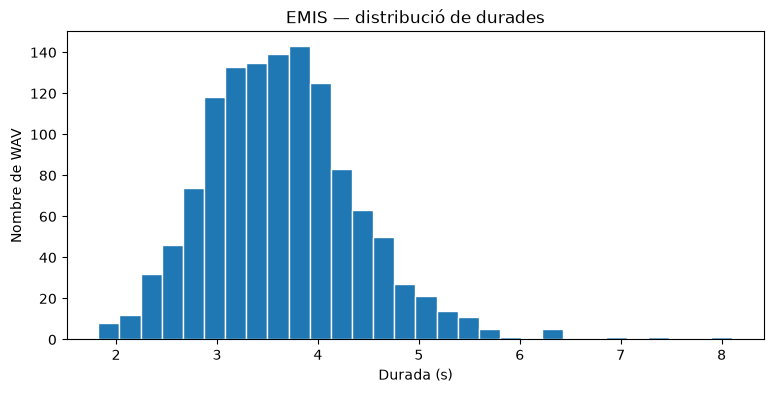

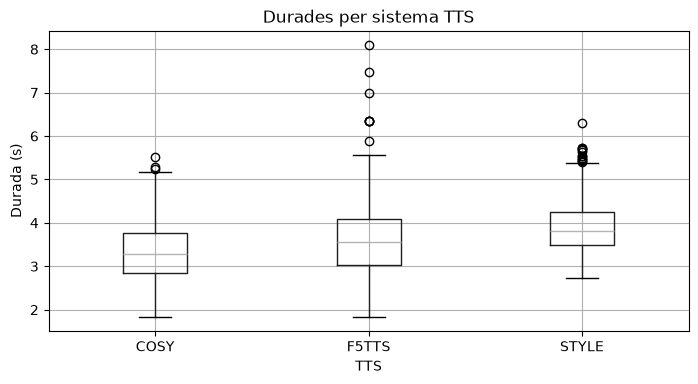

,count,min,median,mean,max
tts_system,,,,,
COSY,416,1.840,3.280,3.354,5.520
F5TTS,416,1.824,3.552,3.655,8.107
STYLE,416,2.723,3.823,3.920,6.298


In [8]:
audio_with_meta = manifest.merge(audio_info, on="zip_member", how="left", validate="one_to_one")
assert audio_with_meta["duration_s"].notna().all()
fig, ax = plt.subplots(figsize=(9,4))
ax.hist(audio_with_meta["duration_s"], bins=30, edgecolor="white")
ax.set(title="EMIS — distribució de durades", xlabel="Durada (s)", ylabel="Nombre de WAV")
plt.show()

fig, ax = plt.subplots(figsize=(8,4))
audio_with_meta.boxplot(column="duration_s", by="tts_system", ax=ax)
ax.set(title="Durades per sistema TTS", xlabel="TTS", ylabel="Durada (s)")
fig.suptitle("")
plt.show()
display(audio_with_meta.groupby("tts_system")["duration_s"].agg(["count","min","median","mean","max"]).round(3))

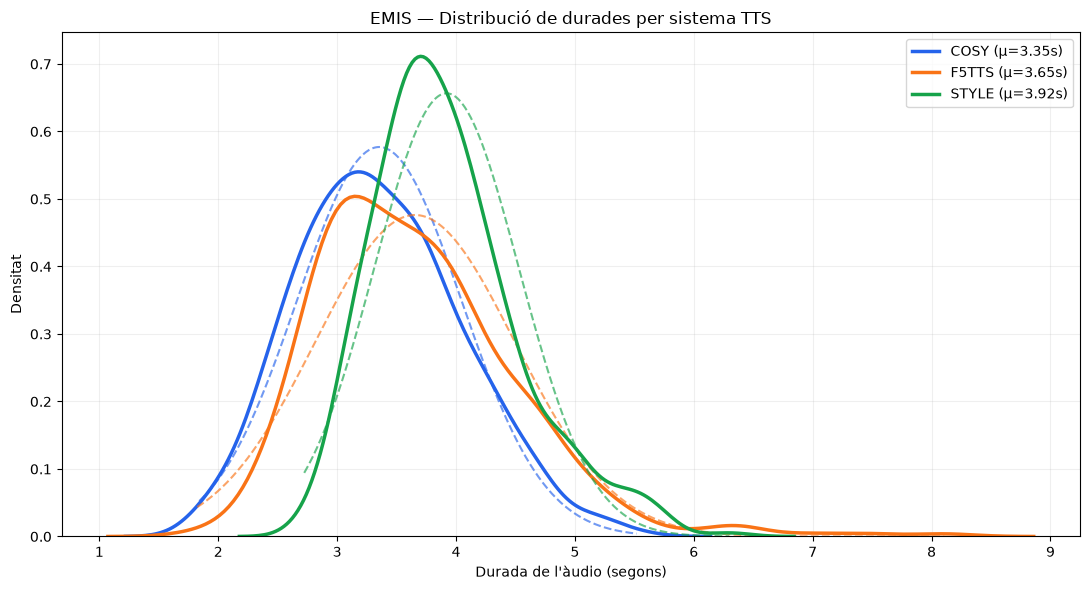

In [16]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

colors = {
    "COSY": "#2563eb",
    "F5TTS": "#f97316",
    "STYLE": "#16a34a"
}

plt.figure(figsize=(11, 6))

for system, color in colors.items():
    durations = audio_with_meta.loc[
        audio_with_meta["tts_system"] == system,
        "duration_s"
    ].dropna().to_numpy()

    mu = durations.mean()
    sigma = durations.std(ddof=1)

    # Distribució empírica
    sns.kdeplot(
        x=durations, color=color, linewidth=2.5,
        label=f"{system} (μ={mu:.2f}s)"
    )

    # Distribució normal ajustada
    x = np.linspace(durations.min(), durations.max(), 300)
    plt.plot(x, norm.pdf(x, mu, sigma),
             color=color, linestyle="--", alpha=0.65)

plt.title("EMIS — Distribució de durades per sistema TTS")
plt.xlabel("Durada de l'àudio (segons)")
plt.ylabel("Densitat")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 7. Casos de control i escolta opcional

Els exemples següents corresponen a mostres utilitzades en els logs. Aquí es reprodueixen des del ZIP sense modificar les dades originals. **Cal que una persona comprovi la frase pronunciada** si volem validar el mapatge àudio–text perceptivament.

In [9]:
from IPython.display import display, Audio
examples = [
    "03_happy_explicit_angry_0012_COSY.wav",
    "07_sad_implicit_angry_0020_STYLE.wav",
    "13_angry_explicit_angry_0020_F5TTS.wav",
]
with zipfile.ZipFile(ZIP_PATH) as archive:
    for filename in examples:
        matches = [name for name in wav_members if Path(name).name == filename]
        if len(matches) != 1:
            print("Exemple no localitzat inequívocament:", filename, matches)
            continue
        member = matches[0]
        row = manifest.loc[manifest["zip_member"] == member]
        print("Fitxer:", filename)
        print("Text associat:", row["text"].iloc[0] if len(row)==1 else "No identificat")
        wav, sr = sf.read(io.BytesIO(archive.read(member)))
        display(Audio(wav, rate=sr))

Fitxer: 03_happy_explicit_angry_0012_COSY.wav
Text associat: Happy tears rolled down my cheeks at the wedding.


Fitxer: 07_sad_implicit_angry_0020_STYLE.wav
Text associat: It’s hard waking up without her beside me.


Fitxer: 13_angry_explicit_angry_0020_F5TTS.wav
Text associat: It’s hard to stay calm when I feel angry.


## 8. Conclusions de l'auditoria i següents passos

**Ja verificat en els logs anteriors:** manifest generat amb 1.248 files, 104 grups de text, distribucions equilibrades per TTS i emoció de generació, 0 nuls als camps declarats, 0 errors de lectura i àudios mono a 24 kHz. Aquest notebook ofereix els controls per tornar-ho a verificar.

**Encara no provat amb aquestes comprovacions:** correspondència fonètica entre cada WAV i la transcripció; percepció humana de l'emoció vocal; compatibilitat entre representacions acústiques i textuals; calibratge dels models; qualitat del mismatch.

**Properes etapes del projecte** (en notebooks separats):

- `02_audio_representation.ipynb`: comparació d'estratègies acústiques (SER com a baseline opcional; regressió VAD, SSL, eGeMAPS), segons decisió metodològica.
- `03_text_representation.ipynb`: representació afectiva textual i avaluació independent.
- `04_mismatch_baselines.ipynb`: comparabilitat, discrepàncies i controls d'errors.
- `05_error_analysis.ipynb`: anàlisi sistemàtica, limitacions i preparació de validació humana.

**Criteri científic:** no interpretar desacord de models com una contradicció humana demostrada.

## 9. Proveniència dels resultats

Font dels resultats històrics: exportació de terminal facilitada en aquesta conversa (`Pasted text(20261014-075756).txt`).

Projecte local observat als logs: `EMIS-Research`, amb `data/raw/audios_EMIS.zip`, `data/raw/text_samples_EMIS.csv`, `data/processed/emis_manifest.csv` i `src/emis_research/build_manifest.py`.

Per deixar constància de qualsevol actualització, executa de nou les cel·les i desa el notebook amb les sortides. No publiquis dades o enregistraments fins a revisar-ne les llicències.

# PAS 1.3 — Cobertura del disseny experimental

In [10]:
group_cols = ["text_category", "text_id", "tts_system"]

coverage = (
    manifest.groupby(group_cols, dropna=False)
    ["generation_emotion"]
    .nunique()
    .reset_index(name="n_emotions")
)

print("Distribució del nombre d'emocions per grup:")
display(coverage["n_emotions"].value_counts().sort_index())

print("\nGrups incomplets (menys de 4 emocions):")
incomplete = coverage[coverage["n_emotions"] < 4]
display(incomplete)

print("\nCobertura per categoria textual i TTS:")
display(
    manifest.groupby(
        ["text_category", "tts_system"]
    )["generation_emotion"]
    .value_counts()
    .unstack(fill_value=0)
)

Distribució del nombre d'emocions per grup:


n_emotions
4    312
Name: count, dtype: int64


Grups incomplets (menys de 4 emocions):


,text_category,text_id,tts_system,n_emotions



Cobertura per categoria textual i TTS:


generation_emotion         angry  happy  neutral  sad
text_category  tts_system                            
angry_explicit COSY           13     13       13   13
               F5TTS          13     13       13   13
               STYLE          13     13       13   13
angry_implicit COSY           13     13       13   13
               F5TTS          13     13       13   13
               STYLE          13     13       13   13
happy_explicit COSY           13     13       13   13
               F5TTS          13     13       13   13
               STYLE          13     13       13   13
happy_implicit COSY           13     13       13   13
               F5TTS          13     13       13   13
               STYLE          13     13       13   13
neutral        COSY           26     26       26   26
               F5TTS          26     26       26   26
               STYLE          26     26       26   26
sad_explicit   COSY           13     13       13   13
               F5TTS          13     13       13   13
               STYLE          13     13       13   13
sad_implicit   COSY           13     13       13   13
               F5TTS          13     13       13   13
               STYLE          13     13       13   13

La distribució ens permetrà estudiar:

* L'efecte de l'emoció vocal mantenint constant el text.
* L'efecte del sistema TTS.
* Les diferències entre emocions explícites, implícites i textos neutres.

IMPORTANT: generation_emotion indica l'emoció utilitzada per generar l'àudio, no necessàriament l'emoció que percebria una persona.

In [11]:
# PAS 1.4 — Verificació de la unicitat factorial

keys = [
    "text_category",
    "text_id",
    "tts_system",
    "generation_emotion",
]

counts = (
    manifest.groupby(keys, dropna=False)
    .size()
    .reset_index(name="n_recordings")
)

print("Total de combinacions:", len(counts))
print("Distribució d'enregistraments per combinació:")
print(counts["n_recordings"].value_counts().sort_index())

assert len(counts) == len(manifest), (
    "Hi ha combinacions factorials duplicades."
)

assert counts["n_recordings"].eq(1).all(), (
    "Alguna combinació té més d'un enregistrament."
)

print("VALIDACIÓ SUPERADA: una gravació per combinació.")

Total de combinacions: 1248
Distribució d'enregistraments per combinació:
n_recordings
1    1248
Name: count, dtype: int64
VALIDACIÓ SUPERADA: una gravació per combinació.


In [12]:
# PAS 1.5 — Auditoria semàntica de les etiquetes

print("COLUMNES DISPONIBLES:")
print(manifest.columns.tolist())

print("\nEXEMPLES DE METADADES:")
display(manifest.head(5))

print("\nVALORS DE CATEGORIES TEXTUALS:")
print(manifest["text_category"].value_counts())

print("\nVALORS D'EMOCIONS DE GENERACIÓ:")
print(manifest["generation_emotion"].value_counts())

COLUMNES DISPONIBLES:
['audio_id', 'zip_member', 'text', 'text_id', 'text_category', 'generation_emotion', 'reference_id', 'tts_system']

EXEMPLES DE METADADES:


,audio_id,zip_member,text,text_id,text_category,generation_emotion,reference_id,tts_system
0,01_angry_explicit_angry_0011_STYLE,01_angry_explicit_angry_0011_STYLE.wav,I'm really angry about what just happened.,01,angry_explicit,angry,11,STYLE
1,01_angry_explicit_angry_0015_COSY,01_angry_explicit_angry_0015_COSY.wav,I'm really angry about what just happened.,01,angry_explicit,angry,15,COSY
2,01_angry_explicit_angry_0019_F5TTS,01_angry_explicit_angry_0019_F5TTS.wav,I'm really angry about what just happened.,01,angry_explicit,angry,19,F5TTS
3,01_angry_explicit_happy_0012_COSY,01_angry_explicit_happy_0012_COSY.wav,I'm really angry about what just happened.,01,angry_explicit,happy,12,COSY
4,01_angry_explicit_happy_0017_F5TTS,01_angry_explicit_happy_0017_F5TTS.wav,I'm really angry about what just happened.,01,angry_explicit,happy,17,F5TTS



VALORS DE CATEGORIES TEXTUALS:
text_category
neutral           312
angry_explicit    156
angry_implicit    156
happy_explicit    156
happy_implicit    156
sad_explicit      156
sad_implicit      156
Name: count, dtype: int64

VALORS D'EMOCIONS DE GENERACIÓ:
generation_emotion
angry      312
happy      312
neutral    312
sad        312
Name: count, dtype: int64


## Conclusions de l'auditoria EMIS

### Resultats estructurals
- 1.248 enregistraments WAV.
- 104 textos x 3 sistemes TTS x 4 emocions de generació.
- 312 grups text–TTS amb les quatre emocions representades.
- 1.248 combinacions factorials úniques.
- Correspondència àudio–text comprovada manualment en 3 mostres.

### Naturalesa de les etiquetes (manifest)
- `text_category` representa la categoria afectiva assignada al contingut textual.
- `generation_emotion` representa l'emoció especificada durant la síntesi de veu.
- Cap de les dues constitueix, per si mateixa, una anotació perceptiva humana.
- El manifest no conté puntuacions humanes directes d'incongruència.
- El significat i el paper experimental de `reference_id` requereixen verificació documental.

### Implicacions metodològiques
- El disseny permet comparacions aparellades mantenint constants text i TTS.
- Cal evitar interpretacions de les etiquetes de generació com a emocions percebudes.
- La validació humana del mismatch continua pendent.
- La distribució neutral té el doble de mostres que cada categoria textual no neutral.
- Cal controlar els agrupaments per text i les possibles dependències associades a les referències de síntesi.

### Estat
Auditoria estructural i de metadades completada en el seu abast inicial. Validació perceptiva exhaustiva i verificació documental pendents.

In [13]:
# PAS 1.7 — Anàlisi de les referències vocals

print("Referències úniques:")
print(manifest["reference_id"].nunique())

print("\nReferències per sistema TTS:")
display(
    manifest.groupby("tts_system")["reference_id"]
    .nunique()
)

print("\nReferències per emoció:")
display(
    manifest.groupby("generation_emotion")["reference_id"]
    .nunique()
)

print("\nRelació entre referència vocal i TTS:")
display(
    manifest.groupby(
        ["reference_id", "tts_system"]
    ).size().unstack(fill_value=0)
)

Referències úniques:
10

Referències per sistema TTS:


tts_system
COSY     10
F5TTS    10
STYLE    10
Name: reference_id, dtype: int64


Referències per emoció:


generation_emotion
angry      10
happy      10
neutral    10
sad        10
Name: reference_id, dtype: int64


Relació entre referència vocal i TTS:


tts_system,COSY,F5TTS,STYLE
reference_id,,,
11,44,48,44
12,55,46,55
13,37,41,37
14,41,43,41
15,43,40,43
16,40,41,40
17,37,38,37
18,40,42,40
19,36,37,36


In [14]:
# PAS 1.8 — Distribució de referències per emoció

reference_emotion = (
    manifest.groupby(
        ["reference_id", "generation_emotion"]
    )
    .size()
    .unstack(fill_value=0)
)

print("Enregistraments per referència i emoció:")
display(reference_emotion)

print("\nPercentatge d'emocions dins de cada referència:")
display(
    (reference_emotion.div(
        reference_emotion.sum(axis=1), axis=0
    ) * 100).round(1)
)

print("\nReferències sense alguna emoció:")
print((reference_emotion == 0).any(axis=1).sum())

Enregistraments per referència i emoció:


generation_emotion,angry,happy,neutral,sad
reference_id,,,,
11,34,38,26,38
12,43,33,42,38
13,26,33,28,28
14,27,22,42,34
15,31,30,35,30
16,30,34,29,28
17,24,20,35,33
18,38,33,26,25
19,22,33,20,34



Percentatge d'emocions dins de cada referència:


generation_emotion,angry,happy,neutral,sad
reference_id,,,,
11,25.0,27.9,19.1,27.9
12,27.6,21.2,26.9,24.4
13,22.6,28.7,24.3,24.3
14,21.6,17.6,33.6,27.2
15,24.6,23.8,27.8,23.8
16,24.8,28.1,24.0,23.1
17,21.4,17.9,31.2,29.5
18,31.1,27.0,21.3,20.5
19,20.2,30.3,18.3,31.2



Referències sense alguna emoció:
0


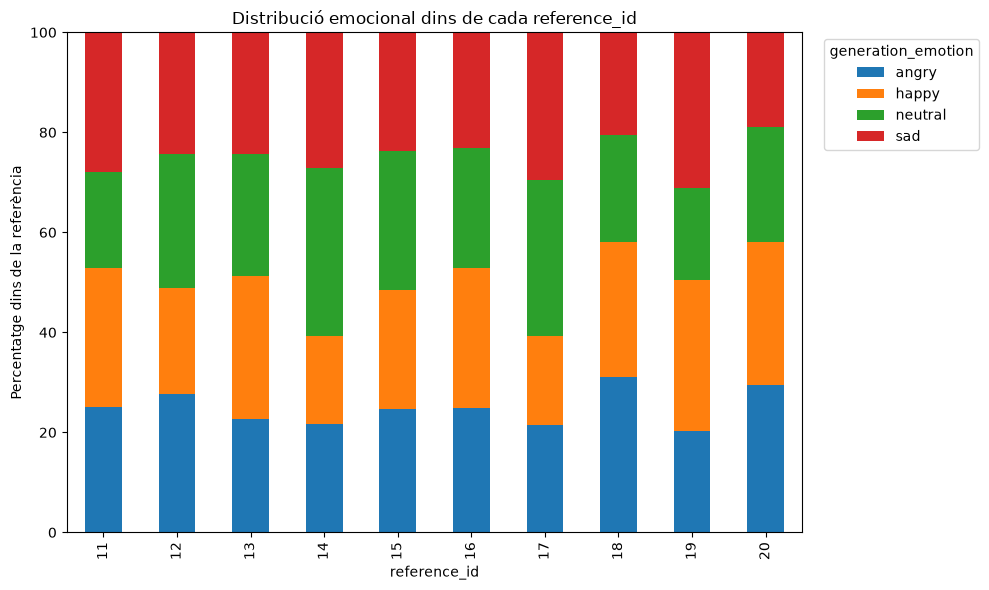

In [15]:
# PAS 1.9 — Gràfica de distribució emocional dins de cada reference_id

import matplotlib.pyplot as plt

# Taula de comptatges per referència i emoció
reference_emotion = (
    manifest.groupby(["reference_id", "generation_emotion"])
    .size()
    .unstack(fill_value=0)
)

# Percentatges dins de cada referència
reference_emotion_pct = (
    reference_emotion.div(reference_emotion.sum(axis=1), axis=0) * 100
).round(1)

# Ordre desitjat de les emocions
emotion_order = ["angry", "happy", "neutral", "sad"]
reference_emotion_pct = reference_emotion_pct[emotion_order]

# Gràfica
ax = reference_emotion_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

ax.set_title("Distribució emocional dins de cada reference_id")
ax.set_xlabel("reference_id")
ax.set_ylabel("Percentatge dins de la referència")
ax.legend(title="generation_emotion", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

### Les representacions acústiques candidates inclouran descriptors interpretables, embeddings SSL i estimacions afectives supervisades. La selecció final dependrà de la fiabilitat, la interpretabilitat, el biaix lèxic i la compatibilitat amb la branca textual. Encara no s'ha seleccionat cap arquitectura definitiva.

comparar checkpoints acústics concrets, amb datasets d'entrenament, tipus de sortida, llicències i limitacions, i seleccionarem el primer experiment pilot sobre EMIS.